# GFS higher-order constrained redistribution: N=12 proof of concept

This small notebook tests one computational idea only.

**Stage 1.** We recover the best saved final unequal-FIP Directed-GFS design for $N=12,n=4$. Its achieved first- and second-order inclusion probabilities are recomputed independently from the saved sample probabilities.

**Stage 2.** We freeze those achieved FIPs and SIPs and redistribute probability over all $\binom{12}{4}=495$ samples. The local prototype—called **GFS-HO** here—uses randomized block linear programs to reduce the variance of the Sen–Yates–Grundy variance estimator for a new auxiliary variable. This is a proof of concept, not a finalized or claimed-novel algorithm.

Ordinary single GFS exchanges do **not** preserve SIPs. Every accepted Stage-2 update therefore solves explicit normalization/FIP/SIP equality constraints. Support is defined consistently as $p_s>10^{-12}$; smaller LP noise is never counted.

In [1]:
from pathlib import Path
import hashlib
import itertools
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import qr
from scipy.optimize import linprog

# Visible, user-editable settings.
N = 12
n = 4
AUX_SEED = 24680
HO_SEED = 97531
HO_MAX_ITER = 120
HO_STAGNATION = 35
HO_BLOCK_SIZE = None  # None => rank-aware automatic choice.
SUPPORT_TOL = 1e-12  # Fixed definition: p_s > 1e-12.
VALIDATION_TOL = 1e-10

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    path for path in (cwd, *cwd.parents)
    if (path / "pyproject.toml").is_file() and (path / "prescribed_sip").is_dir()
)
SOURCE_ROOT = Path("/home/bardia/Desktop/GFS_Prescribed_SIP_Final_Results")
RESULTS_DIR = PROJECT_ROOT / "prescribed_sip" / "higher_order_demo_N12"


In [2]:
def support_diagnostics(probabilities, total_samples, tol=SUPPORT_TOL):
    """Return support count and fraction using the strict fixed threshold."""
    support_size = int(np.count_nonzero(np.asarray(probabilities) > tol))
    return support_size, support_size / int(total_samples)


def enumerate_problem(N, n):
    """Enumerate fixed-size samples and the full probability/FIP/SIP matrix."""
    samples = np.asarray(list(itertools.combinations(range(N), n)), dtype=int)
    K = len(samples)
    membership = np.zeros((K, N), dtype=float)
    membership[np.arange(K)[:, None], samples] = 1.0
    pairs = list(itertools.combinations(range(N), 2))
    pair_membership = np.column_stack(
        [membership[:, i] * membership[:, j] for i, j in pairs]
    )
    A = np.vstack([np.ones(K), membership.T, pair_membership.T])
    return samples, membership, pairs, pair_membership, A


def inclusion_moments(probabilities, membership, pairs, pair_membership):
    """Compute first- and second-order inclusion probabilities independently."""
    probabilities = np.asarray(probabilities, dtype=float)
    pi = membership.T @ probabilities
    Pi = np.diag(pi.copy())
    pair_values = pair_membership.T @ probabilities
    for value, (i, j) in zip(pair_values, pairs):
        Pi[i, j] = Pi[j, i] = value
    return pi, Pi


def independent_constraint_rows(A, tol=1e-11):
    """Select a numerically independent row basis without changing feasibility."""
    rank = int(np.linalg.matrix_rank(A, tol=tol))
    _, _, pivots = qr(A.T, mode="economic", pivoting=True)
    return np.sort(np.asarray(pivots[:rank], dtype=int)), rank


def design_entropy(probabilities):
    positive = np.asarray(probabilities) > 0.0
    p = np.asarray(probabilities)[positive]
    return float(-np.dot(p, np.log(p)))


def design_diagnostics(probabilities, membership, pairs, pair_membership,
                       pi_fixed, Pi_fixed, v_values, v_ht, costs,
                       iteration, accepted_iteration, start_time):
    pi, Pi = inclusion_moments(probabilities, membership, pairs, pair_membership)
    pair_error = np.asarray([Pi[i, j] - Pi_fixed[i, j] for i, j in pairs])
    J = float(np.dot(probabilities, costs))
    support_size, support_fraction = support_diagnostics(probabilities, len(probabilities))
    scale = abs(v_ht)
    return {
        "iteration": int(iteration),
        "accepted_iteration": int(accepted_iteration),
        "J": J,
        "RelativeVarV": J / (v_ht * v_ht) if scale > 0 else np.nan,
        "CV_V": np.sqrt(max(J, 0.0)) / scale if scale > 0 else np.nan,
        "E_Vhat": float(np.dot(probabilities, v_values)),
        "V_HT": float(v_ht),
        "max_FIP_drift": float(np.max(np.abs(pi - pi_fixed))),
        "SIP_RMSE_drift": float(np.sqrt(np.mean(pair_error ** 2))),
        "max_SIP_drift": float(np.max(np.abs(pair_error))),
        "support_size": support_size,
        "support_fraction": support_fraction,
        "entropy": design_entropy(probabilities),
        "runtime": float(time.perf_counter() - start_time),
    }


def block_optimize(p0, costs, A, membership, pairs, pair_membership, *,
                   max_iter, stagnation, block_size, seed, validation_tol,
                   v_values, v_ht):
    """Randomized block LP redistribution with exact moment contributions fixed."""
    p = np.asarray(p0, dtype=float).copy()
    b_full = A @ p
    pi_fixed, Pi_fixed = inclusion_moments(p, membership, pairs, pair_membership)
    independent_rows, rank = independent_constraint_rows(A)
    A_reduced = A[independent_rows]
    K = len(p)
    if block_size is None:
        block_size = min(K, max(2 * rank, rank + 32))
    block_size = int(block_size)
    if not rank < block_size <= K:
        raise ValueError(f"block_size must be in ({rank}, {K}], got {block_size}")

    rng = np.random.default_rng(seed)
    start_time = time.perf_counter()
    accepted = 0
    stagnant = 0
    rows = [design_diagnostics(
        p, membership, pairs, pair_membership, pi_fixed, Pi_fixed,
        v_values, v_ht, costs, 0, 0, start_time,
    )]
    current_J = rows[0]["J"]

    for iteration in range(1, int(max_iter) + 1):
        active = np.flatnonzero(p > SUPPORT_TOL)
        inactive = np.flatnonzero(p <= SUPPORT_TOL)
        desired_active = min(len(active), max(rank + 4, (2 * block_size) // 3))
        chosen_active = (
            rng.choice(active, size=desired_active, replace=False)
            if desired_active else np.empty(0, dtype=int)
        )
        remaining = block_size - len(chosen_active)
        pool = np.setdiff1d(np.arange(K), chosen_active, assume_unique=False)
        chosen_other = rng.choice(pool, size=remaining, replace=False)
        block = np.sort(np.r_[chosen_active, chosen_other])

        A_block = A_reduced[:, block]
        rhs = A_block @ p[block]
        lp = linprog(
            costs[block], A_eq=A_block, b_eq=rhs,
            bounds=(0.0, None), method="highs",
        )
        if not lp.success:
            stagnant += 1
        else:
            candidate = p.copy()
            candidate[block] = lp.x
            candidate_J = float(np.dot(candidate, costs))
            improvement_floor = max(1e-14, 1e-12 * max(1.0, abs(current_J)))
            full_residual = float(np.max(np.abs(A @ candidate - b_full)))
            if candidate_J < current_J - improvement_floor:
                if full_residual > validation_tol:
                    raise RuntimeError(
                        f"Accepted block would drift from fixed constraints: {full_residual:.3e}"
                    )
                p = candidate
                current_J = candidate_J
                accepted += 1
                stagnant = 0
                row = design_diagnostics(
                    p, membership, pairs, pair_membership, pi_fixed, Pi_fixed,
                    v_values, v_ht, costs, iteration, accepted, start_time,
                )
                if max(row["max_FIP_drift"], row["max_SIP_drift"]) > validation_tol:
                    raise RuntimeError("FIP/SIP drift exceeded validation tolerance")
                rows.append(row)
            else:
                stagnant += 1
        if stagnant >= stagnation:
            break

    convergence = pd.DataFrame(rows)
    return {
        "probabilities": p,
        "convergence": convergence,
        "constraint_rank": rank,
        "block_size": block_size,
        "attempted_iterations": int(iteration),
        "accepted_iterations": accepted,
        "min_support_size": int(convergence["support_size"].min()),
        "max_support_size": int(convergence["support_size"].max()),
        "runtime": float(time.perf_counter() - start_time),
    }


def solve_exact_lp(costs, A, b_full, validation_tol):
    """Global 495-variable LP oracle under the identical moment constraints."""
    independent_rows, rank = independent_constraint_rows(A)
    started = time.perf_counter()
    lp = linprog(
        costs, A_eq=A[independent_rows], b_eq=b_full[independent_rows],
        bounds=(0.0, None), method="highs",
    )
    runtime = time.perf_counter() - started
    if not lp.success:
        raise RuntimeError(f"Exact LP failed: {lp.message}")
    residual = float(np.max(np.abs(A @ lp.x - b_full)))
    if residual > validation_tol:
        raise RuntimeError(f"Exact LP constraint drift {residual:.3e}")
    return lp.x, runtime, rank, residual


## Recover and freeze the achieved Directed-GFS moments

The final target is loaded rather than regenerated. Among the 30 saved final-study Directed-GFS repetitions, the notebook selects the design with the smallest stored SIP RMSE and reconstructs its 495-vector of probabilities. The actual achieved moments—not the target moments—become the Stage-2 equality constraints.

In [3]:
if not SOURCE_ROOT.is_dir():
    raise FileNotFoundError(f"Saved final unequal-FIP study not found: {SOURCE_ROOT}")

target_dir = SOURCE_ROOT / "targets" / "N12_n4"
directed_results = []
for result_path in sorted((SOURCE_ROOT / "raw_runs").glob("N12_n4_2_r*/result.json")):
    result = json.loads(result_path.read_text())
    if result.get("RMSE") is not None and result.get("Status") == "completed":
        directed_results.append((float(result["RMSE"]), result_path, result))
if not directed_results:
    raise FileNotFoundError("No saved completed N=12 Directed-GFS distributions found")

stored_rmse, best_result_path, best_result = min(directed_results, key=lambda item: item[0])
best_design_path = best_result_path.with_name("design.json")
saved_design = json.loads(best_design_path.read_text())
pi_target_path = target_dir / "pi.npy"
Pi_star_path = target_dir / "Pi_star.npy"
pi_target = np.load(pi_target_path)
Pi_star = np.load(Pi_star_path)

samples, membership, pairs, pair_membership, A = enumerate_problem(N, n)
K = len(samples)
assert K == 495
sample_index = {tuple(sample): idx for idx, sample in enumerate(samples)}
p_initial = np.zeros(K)
for sample, probability in zip(saved_design["samples"], saved_design["probabilities"]):
    p_initial[sample_index[tuple(sorted(sample))]] += float(probability)

pi_fixed, Pi_fixed = inclusion_moments(p_initial, membership, pairs, pair_membership)
target_pair_error = np.asarray([Pi_fixed[i, j] - Pi_star[i, j] for i, j in pairs])
target_fip_error = float(np.max(np.abs(pi_fixed - pi_target)))
target_sip_rmse = float(np.sqrt(np.mean(target_pair_error ** 2)))
target_sip_max = float(np.max(np.abs(target_pair_error)))
initial_support_size, initial_support_fraction = support_diagnostics(p_initial, K)
minimum_required_sip = min(Pi_fixed[i, j] for i, j in pairs)
if minimum_required_sip <= SUPPORT_TOL:
    raise RuntimeError(
        f"Required achieved SIP is zero/numerically zero: minimum={minimum_required_sip:.17g}"
    )

print("Recovered exact saved objects:")
print("  prescribed FIPs:", pi_target_path)
print("  target SIPs:     ", Pi_star_path)
print("  selected result: ", best_result_path)
print("  selected design: ", best_design_path)
print(f"Selected {best_result_path.parent.name}; stored RMSE={stored_rmse:.17g}")
print(f"max |pi0-pi_target|={target_fip_error:.3e}")
print(f"RMSE(Pi0,Pi_star)={target_sip_rmse:.17g}")
print(f"max |Pi0-Pi_star|={target_sip_max:.3e}")
print(f"Initial support={initial_support_size}/{K} ({initial_support_fraction:.15f})")
print(f"Minimum required off-diagonal Pi0={minimum_required_sip:.6e}")


Recovered exact saved objects:
  prescribed FIPs: /home/bardia/Desktop/GFS_Prescribed_SIP_Final_Results/targets/N12_n4/pi.npy
  target SIPs:      /home/bardia/Desktop/GFS_Prescribed_SIP_Final_Results/targets/N12_n4/Pi_star.npy
  selected result:  /home/bardia/Desktop/GFS_Prescribed_SIP_Final_Results/raw_runs/N12_n4_2_r17/result.json
  selected design:  /home/bardia/Desktop/GFS_Prescribed_SIP_Final_Results/raw_runs/N12_n4_2_r17/design.json
Selected N12_n4_2_r17; stored RMSE=9.5284722822674435e-11
max |pi0-pi_target|=3.331e-16
RMSE(Pi0,Pi_star)=9.5284719332677524e-11
max |Pi0-Pi_star|=4.090e-10
Initial support=314/495 (0.634343434343434)
Minimum required off-diagonal Pi0=5.418436e-03


## New auxiliary variable and Sen–Yates–Grundy estimator

The positive lognormal vector below is generated independently with `AUX_SEED`. It was not used to construct the target or the Directed-GFS design and can be replaced directly by a study variable.

For every sample $s$, the notebook caches $v_s=\widehat V_{SYG}(s)$. With fixed FIPs and SIPs, $E_p[v_s]=V_{HT}$ for every feasible Stage-2 design, while $\operatorname{Var}_p(v_s)$ can change through higher-order structure.

In [4]:
rng_aux = np.random.default_rng(AUX_SEED)
z = rng_aux.lognormal(mean=0.0, sigma=0.8, size=N)
ratio = z / pi_fixed
Delta = Pi_fixed - np.outer(pi_fixed, pi_fixed)

pair_terms = np.asarray([
    -(Delta[i, j] / Pi_fixed[i, j]) * (ratio[i] - ratio[j]) ** 2
    for i, j in pairs
])
v_values = pair_membership @ pair_terms
V_HT = float(-sum(
    Delta[i, j] * (ratio[i] - ratio[j]) ** 2 for i, j in pairs
))
costs = (v_values - V_HT) ** 2
J_initial = float(np.dot(p_initial, costs))
second_moment_J_initial = float(np.dot(p_initial, v_values ** 2) - V_HT ** 2)
if not np.isclose(J_initial, second_moment_J_initial, rtol=1e-11, atol=1e-10):
    raise RuntimeError("Centered and second-moment forms of Var(Vhat) disagree")

print("Auxiliary variable z (unit-ID order):")
print(np.array2string(z, precision=17, separator=", "))
print(f"V_HT={V_HT:.17g}")
print(f"Initial Var(Vhat)={J_initial:.17g}")
print(f"Second-moment cross-check={second_moment_J_initial:.17g}")


Auxiliary variable z (unit-ID order):
[1.1273650290892072 , 0.4836754461372087 , 1.5048904861996175 ,
 0.2823283385015461 , 2.7973088636867676 , 4.26882431886527   ,
 0.9452387562985247 , 1.7211928049809457 , 1.085552800646873  ,
 1.4465821101850211 , 0.34087374760729894, 1.32649626253678   ]
V_HT=35.379242129659225
Initial Var(Vhat)=27689.314262496464
Second-moment cross-check=27689.314262496475


## Iterative GFS-HO prototype and exact LP oracle

Each attempted block includes active and zero-probability samples. The block LP keeps that block's exact contribution to the independent normalization/FIP/SIP constraints; variables outside the block remain fixed. An update is accepted only when the objective decreases and the complete constraints pass strict validation. The global LP uses the identical constraints and serves only as an oracle.

In [5]:
ho_result = block_optimize(
    p_initial, costs, A, membership, pairs, pair_membership,
    max_iter=HO_MAX_ITER,
    stagnation=HO_STAGNATION,
    block_size=HO_BLOCK_SIZE,
    seed=HO_SEED,
    validation_tol=VALIDATION_TOL,
    v_values=v_values,
    v_ht=V_HT,
)
p_optimized = ho_result["probabilities"]
convergence = ho_result["convergence"]

b_fixed = A @ p_initial
p_exact, exact_runtime, exact_rank, exact_residual = solve_exact_lp(
    costs, A, b_fixed, VALIDATION_TOL
)

J_optimized = float(np.dot(p_optimized, costs))
J_exact = float(np.dot(p_exact, costs))
reduction_pct = 100.0 * (J_initial - J_optimized) / J_initial
possible_denominator = J_initial - J_exact
possible_improvement_pct = (
    100.0 * (J_initial - J_optimized) / possible_denominator
    if possible_denominator > 0 else np.nan
)

print(f"Constraint rank={ho_result['constraint_rank']} of {A.shape[0]} rows")
print(f"Automatic block size={ho_result['block_size']} of {K} samples")
print(f"Accepted iterations={ho_result['accepted_iterations']} ")
print(f"Attempted iterations={ho_result['attempted_iterations']}")
print(f"J_initial={J_initial:.17g}")
print(f"J_GFS_HO={J_optimized:.17g}")
print(f"J_exact_oracle={J_exact:.17g}")
print(f"Reduction={reduction_pct:.6f}%")
print(f"Possible improvement achieved={possible_improvement_pct:.6f}%")
print(
    "Support range during GFS-HO: "
    f"{ho_result['min_support_size']} to {ho_result['max_support_size']} of {K}"
)


Constraint rank=66 of 79 rows
Automatic block size=132 of 495 samples
Accepted iterations=59 
Attempted iterations=120
J_initial=27689.314262496464
J_GFS_HO=12414.860610361422
J_exact_oracle=12414.860610361407
Reduction=55.163712%
Possible improvement achieved=100.000000%
Support range during GFS-HO: 66 to 314 of 495


## Validation, summaries, and saved artifacts

In [6]:
def summary_row(method, p, runtime):
    row = design_diagnostics(
        p, membership, pairs, pair_membership, pi_fixed, Pi_fixed,
        v_values, V_HT, costs, 0, 0, time.perf_counter(),
    )
    second_moment = float(np.dot(p, v_values ** 2) - V_HT ** 2)
    row.update({
        "Method": method,
        "Second-moment Var(Vhat)": second_moment,
        "runtime": float(runtime),
    })
    return row


summary_rows = [
    summary_row("Initial Directed GFS", p_initial, 0.0),
    summary_row("GFS-HO optimized", p_optimized, ho_result["runtime"]),
    summary_row("Exact LP oracle", p_exact, exact_runtime),
]
summary = pd.DataFrame(summary_rows).rename(columns={
    "J": "Var(Vhat)",
    "RelativeVarV": "Relative Var(Vhat)",
    "CV_V": "CV(Vhat)",
    "E_Vhat": "E[Vhat]",
    "max_FIP_drift": "max FIP drift",
    "SIP_RMSE_drift": "SIP RMSE drift",
    "max_SIP_drift": "max SIP drift",
    "support_size": "support size",
    "support_fraction": "support fraction",
})
summary = summary[[
    "Method", "Var(Vhat)", "Relative Var(Vhat)", "CV(Vhat)",
    "E[Vhat]", "V_HT", "max FIP drift", "SIP RMSE drift",
    "max SIP drift", "support size", "support fraction", "entropy", "runtime",
    "Second-moment Var(Vhat)",
]]

for _, row in summary.iterrows():
    moment_tol = 1e-9 * max(1.0, abs(V_HT))
    if abs(row["E[Vhat]"] - V_HT) > moment_tol:
        raise RuntimeError(f"{row['Method']} has E[Vhat] != V_HT")
    if max(row["max FIP drift"], row["max SIP drift"]) > VALIDATION_TOL:
        raise RuntimeError(f"{row['Method']} violates frozen FIP/SIP constraints")
    if not np.isclose(
        row["Var(Vhat)"], row["Second-moment Var(Vhat)"],
        rtol=1e-10, atol=1e-9,
    ):
        raise RuntimeError(f"{row['Method']} fails second-moment cross-check")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
pd.DataFrame({"unit_id": np.arange(N), "z": z}).to_csv(
    RESULTS_DIR / "auxiliary_variable.csv", index=False, float_format="%.17g"
)

def design_frame(probabilities):
    frame = pd.DataFrame({
        "sample": [" ".join(map(str, sample)) for sample in samples],
        "probability": probabilities,
    })
    frame["support_at_1e-12"] = frame["probability"] > SUPPORT_TOL
    return frame

design_frame(p_initial).to_csv(
    RESULTS_DIR / "starting_design.csv", index=False, float_format="%.17g"
)
design_frame(p_optimized).to_csv(
    RESULTS_DIR / "optimized_design.csv", index=False, float_format="%.17g"
)
design_frame(p_exact).to_csv(
    RESULTS_DIR / "exact_oracle_design.csv", index=False, float_format="%.17g"
)
convergence.to_csv(RESULTS_DIR / "convergence.csv", index=False, float_format="%.17g")
summary.to_csv(RESULTS_DIR / "summary.csv", index=False, float_format="%.17g")
(RESULTS_DIR / "summary.tex").write_text(
    summary.to_latex(index=False, float_format=lambda value: f"{value:.6e}")
)

configuration = {
    "N": N, "n": n, "possible_samples": K,
    "AUX_SEED": AUX_SEED, "HO_SEED": HO_SEED,
    "HO_MAX_ITER": HO_MAX_ITER, "HO_STAGNATION": HO_STAGNATION,
    "HO_BLOCK_SIZE_requested": HO_BLOCK_SIZE,
    "HO_BLOCK_SIZE_used": ho_result["block_size"],
    "constraint_rank": ho_result["constraint_rank"],
    "SUPPORT_TOL": SUPPORT_TOL, "support_definition": "p_s > 1e-12",
    "VALIDATION_TOL": VALIDATION_TOL,
    "selected_saved_run": best_result_path.parent.name,
    "source_files": {
        "pi_target": str(pi_target_path), "Pi_star": str(Pi_star_path),
        "result": str(best_result_path), "design": str(best_design_path),
    },
    "source_SHA256": {
        str(path): hashlib.sha256(path.read_bytes()).hexdigest()
        for path in (pi_target_path, Pi_star_path, best_result_path, best_design_path)
    },
    "accepted_iterations": ho_result["accepted_iterations"],
    "attempted_iterations": ho_result["attempted_iterations"],
    "minimum_support_during_optimization": ho_result["min_support_size"],
    "maximum_support_during_optimization": ho_result["max_support_size"],
    "reduction_percent": reduction_pct,
    "possible_improvement_achieved_percent": possible_improvement_pct,
}
(RESULTS_DIR / "configuration.json").write_text(json.dumps(configuration, indent=2) + "\n")

validation_lines = [
    "GFS higher-order constrained redistribution: validation",
    f"Selected saved Directed-GFS run: {best_result_path.parent.name}",
    f"Support definition: p_s > {SUPPORT_TOL:.0e} (strict)",
    f"Possible samples C(12,4): {K}",
    f"Original Directed-GFS RMSE to Pi_star: {target_sip_rmse:.17g}",
    f"Original Directed-GFS max SIP error to Pi_star: {target_sip_max:.17g}",
    f"Original Directed-GFS max FIP error to target: {target_fip_error:.17g}",
    f"Minimum required off-diagonal achieved SIP: {minimum_required_sip:.17g}",
    f"Minimum support during GFS-HO: {ho_result['min_support_size']}",
    f"Maximum support during GFS-HO: {ho_result['max_support_size']}",
]
for _, row in summary.iterrows():
    validation_lines.extend([
        "",
        f"[{row['Method']}]",
        f"Var(Vhat): {row['Var(Vhat)']:.17g}",
        f"E[Vhat]-V_HT: {row['E[Vhat]'] - V_HT:.17g}",
        f"max FIP drift: {row['max FIP drift']:.17g}",
        f"SIP RMSE drift: {row['SIP RMSE drift']:.17g}",
        f"max SIP drift: {row['max SIP drift']:.17g}",
        f"support size: {int(row['support size'])}",
        f"support fraction: {row['support fraction']:.17g}",
    ])
validation_lines.extend([
    "",
    f"V_HT unchanged for all designs: {V_HT:.17g}",
    f"Exact LP full constraint residual: {exact_residual:.17g}",
    "VALIDATION PASSED",
])
(RESULTS_DIR / "validation.txt").write_text("\n".join(validation_lines) + "\n")

print(summary.to_string(index=False))
print(f"\nOriginal Directed-GFS SIP RMSE to Pi_star: {target_sip_rmse:.17g}")
print(f"All outputs saved under: {RESULTS_DIR}")


              Method    Var(Vhat)  Relative Var(Vhat)  CV(Vhat)   E[Vhat]      V_HT  max FIP drift  SIP RMSE drift  max SIP drift  support size  support fraction  entropy  runtime  Second-moment Var(Vhat)
Initial Directed GFS 27689.314262           22.121529  4.703353 35.379242 35.379242   0.000000e+00    0.000000e+00   0.000000e+00           314          0.634343 4.044334 0.000000             27689.314262
    GFS-HO optimized 12414.860610            9.918473  3.149361 35.379242 35.379242   5.495604e-15    2.683107e-15   9.006684e-15            66          0.133333 3.673161 1.347676             12414.860610
     Exact LP oracle 12414.860610            9.918473  3.149361 35.379242 35.379242   4.329870e-15    1.564598e-15   5.731526e-15            66          0.133333 3.673161 0.023515             12414.860610

Original Directed-GFS SIP RMSE to Pi_star: 9.5284719332677524e-11
All outputs saved under: /home/bardia/projects/graphical-sampling/prescribed_sip/higher_order_demo_N12


## Convergence figure

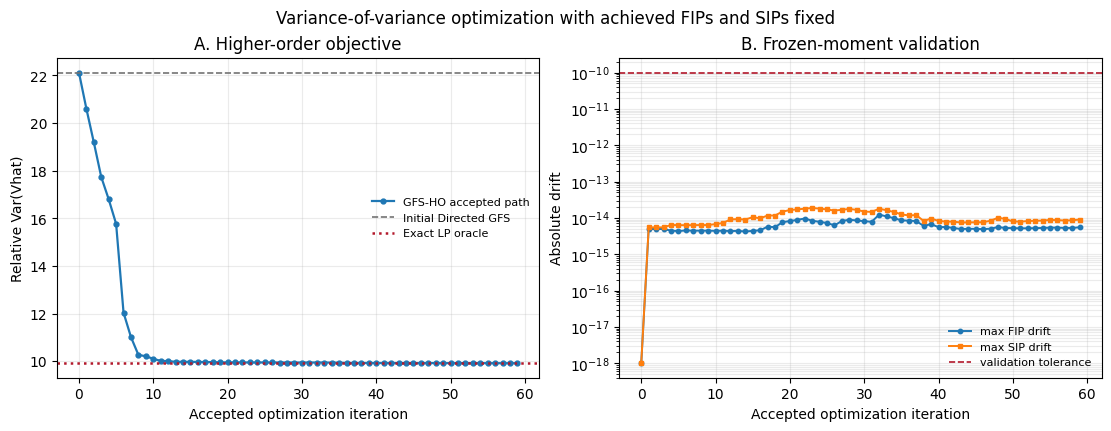

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2), constrained_layout=True)

x_axis = convergence["accepted_iteration"]
axes[0].plot(x_axis, convergence["RelativeVarV"], marker="o", ms=3.5, lw=1.6,
             label="GFS-HO accepted path")
axes[0].axhline(J_initial / V_HT ** 2, color="0.45", ls="--", lw=1.2,
                label="Initial Directed GFS")
axes[0].axhline(J_exact / V_HT ** 2, color="#b2182b", ls=":", lw=1.8,
                label="Exact LP oracle")
axes[0].set(xlabel="Accepted optimization iteration", ylabel="Relative Var(Vhat)",
            title="A. Higher-order objective")
axes[0].grid(alpha=0.25)
axes[0].legend(frameon=False, fontsize=8)

floor = 1e-18
axes[1].semilogy(x_axis, np.maximum(convergence["max_FIP_drift"], floor),
                 marker="o", ms=3.2, lw=1.4, label="max FIP drift")
axes[1].semilogy(x_axis, np.maximum(convergence["max_SIP_drift"], floor),
                 marker="s", ms=3.2, lw=1.4, label="max SIP drift")
axes[1].axhline(VALIDATION_TOL, color="#b2182b", ls="--", lw=1.2,
                label="validation tolerance")
axes[1].set(xlabel="Accepted optimization iteration", ylabel="Absolute drift",
            title="B. Frozen-moment validation")
axes[1].grid(alpha=0.25, which="both")
axes[1].legend(frameon=False, fontsize=8)

fig.suptitle("Variance-of-variance optimization with achieved FIPs and SIPs fixed")
fig.savefig(RESULTS_DIR / "convergence.png", dpi=220, bbox_inches="tight")
fig.savefig(RESULTS_DIR / "convergence.pdf", bbox_inches="tight")
plt.show()


## Interpretation

The comparison separates two questions. The original Directed-GFS SIP error measures how closely Stage 1 matched the prescribed target. Stage 2 instead fixes the **actually achieved** FIPs and SIPs, so the HT variance $V_{HT}$ and $E[\widehat V_{SYG}]$ remain fixed. Any reduction in $\operatorname{Var}(\widehat V_{SYG})$ therefore comes from redistributing higher-order sample probabilities. The exact LP quantifies the best attainable value for this finite $N=12$ problem; it is an oracle benchmark rather than the proposed iterative procedure.